<div style="background:#1B2A49; border-left:12px solid #C8102E; border-radius:16px; padding:40px; text-align:center; color:white;">

<img src="https://moria.aurens.com/organizations/497d3acf-35c0-4c90-8754-d5e71162119b/logos/3215d7-271.png" width="240" style="background:white; padding:10px; border-radius:10px;">

<h1 style="color:white; margin-top:20px;">Colegio Universitario de Cartago</h1>
<h2 style="color:#F2A900;">Minería de Datos II</h2>
<h3 style="color:white;">Examen 2</h3>

<hr style="border-color:#F2A900;">

<p><b style="color:#F2A900;">Profesor:</b> Ronald Códoba Vega</p>
<p><b style="color:#F2A900;">Integrantes:</b><br>Johel Barquero Carvajal<br>Sharon Obando Gómez<br>Fabián Brenes Loría<br>Steven Vindas Rivera<br>Marisol Víquez Rivera</p>
<p><b style="color:#F2A900;">Fecha de entrega:</b> 10 de noviembre de 2026</p>

</div>

--------------------

### Justificación del tamaño de la muestra

Para las reglas de asociación se usó una muestra de **2,000 registros**. Se seleccionaron facturas completas con semilla fija para conservar cada canasta de compra y poder reproducir la muestra.

**¿Por qué una muestra?** Los algoritmos Apriori, ECLAT y FP-Growth son costosos con más de 500 mil registros. Con 2,000 se ejecutan en segundos, se pueden comparar entre sí y generan una cantidad de reglas que sí se puede interpretar (318 itemsets y 370 reglas con soporte 3 y confianza 0,5).

**CRISP-DM y EDA** se hicieron con el conjunto completo, porque ahí interesa describir el negocio y la calidad de los datos, y las estadísticas son más confiables con toda la información.

--------------------------

### 1. CRISP-DM

#### Fase 1: Comprensión del negocio

**Contexto.** Comercio en línea de regalos y artículos decorativos. Entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011 registró 25 900 facturas y 541 909 líneas de producto. Vende a 38 países, pero el Reino Unido concentra el 91,4 % de las filas.

**Problema de negocio.** El comercio tiene muchas ventas, pero no sabe de forma sistemática qué productos se compran juntos. Con miles de productos y una densidad de cesta de solo 0,69 %, es imposible descubrirlo a simple vista.

**Objetivos de negocio**
- Identificar combinaciones de productos para hacer venta cruzada en el sitio web.
- Proponer paquetes (bundles) con productos que se compran juntos.
- Comparar el mercado nacional con el internacional y revisar si los patrones se mantienen en el tiempo.

**Objetivos de minería de datos**
- Encontrar conjuntos frecuentes de productos con Apriori, ECLAT y FP-Growth.
- Generar reglas de asociación y evaluarlas con soporte, confianza y lift.

**Criterios de éxito**
- Negocio: al menos 10 reglas útiles (soporte ≥ 1 %, confianza ≥ 0,5 y lift ≥ 1,2) y 3 propuestas de paquete.
- Minería: que los tres algoritmos den los mismos conjuntos frecuentes con el mismo soporte y comparar sus tiempos.

**Restricciones y supuestos**
- Es un solo comercio y un solo periodo, y diciembre de 2011 está incompleto.
- El 24,93 % de las filas no tiene `CustomerID` y no hay datos de costos ni márgenes.
- Se asume que una factura equivale a una cesta de compra y que basta con saber si un producto está o no en la factura.

#### Fase 2: Comprensión de los datos

**Descripción.** El archivo `Online Retail.xlsx` tiene 541 909 registros y 8 atributos, con 25 900 facturas, 4 372 clientes y 38 países. Su estructura coincide con el conjunto público *Online Retail* de UCI (por confirmar).
- Identificadores: `InvoiceNo`, `StockCode`, `CustomerID`.
- Categóricas: `Country`, `Description`.
- Numéricas: `Quantity`, `UnitPrice`.
- Temporal: `InvoiceDate`.

**Calidad inicial de los datos**
- Faltantes: `CustomerID` (24,93 %) y `Description` (0,27 %).
- 5 268 filas duplicadas exactas (0,97 %).
- 2 515 precios en cero y miles de cantidades negativas (cancelaciones y ajustes).
- El 14,8 % de las facturas son cancelaciones (prefijo C).
- 33 códigos que no son productos (por ejemplo `POST` y `BANK CHARGES`).
- 650 códigos con más de una descripción y espacios sobrantes en los nombres.
- Valores extremos: cantidades de ±80 995 y precios de hasta 38 970.

**Depuración.** Se conservaron solo las líneas de venta válidas: sin cancelaciones, con cantidad y precio mayores que cero, con código de producto real y con descripción. Además se eliminaron duplicados y se unificó la descripción de cada código.

**Exploración inicial**
- Las ventas crecen de septiembre a noviembre de 2011; diciembre baja porque los datos llegan solo hasta el día 9.
- No hay ventas los sábados; el jueves es el día más fuerte y el pico de compras es al mediodía.
- Las cestas son muy variables: mediana de 15 productos por factura y máximo de 1 106.
- Productos más frecuentes: *White Hanging Heart T-Light Holder*, *Jumbo Bag Red Retrospot* y *Regency Cakestand 3 Tier*.
- Hay una cola larga: pocos productos aparecen en muchas facturas y la mayoría en muy pocas.

**Conclusión.** El dataset es de naturaleza transaccional y es adecuado para reglas de asociación. Por su alta dispersión se necesitan soportes bajos, y la depuración es obligatoria.

----

### 2. EDA

In [ ]:
# Importamos la clase LimpiezaOnlineRetail desde el módulo limpieza_datos del paquete eda

from eda.limpieza_datos import LimpiezaOnlineRetail

In [ ]:
# Limpieza del dataset de ventas online retail utilizando la clase LimpiezaOnlineRetail

limpieza = LimpiezaOnlineRetail("../eda/Online Retail.xlsx")

In [21]:
# Cargamos los datos limpios utilizando el método cargar() de la clase LimpiezaOnlineRetail

datos = limpieza.cargar()
print("Filas y columnas originales:", datos.shape)
datos.head()

Filas y columnas originales: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [22]:
# Se crea un nuevo DataFrame con los datos limpios utilizando el método limpiar() de la clase LimpiezaOnlineRetail

datos_limpios = limpieza.limpiar()
print("Filas y columnas después de limpiar:", datos_limpios.shape)

Filas y columnas después de limpiar: (391147, 12)


In [ ]:
# Resumen de los datos limpios

limpieza.resumen()

,paso,filas_eliminadas
0,Duplicados,5268
1,Cancelaciones (factura con C),9251
2,Códigos que no son producto,2406
3,Cantidad o precio <= 0,2480
4,Líneas de más de £10.000,3
5,Description nula,0
6,CustomerID nulo,131354


In [ ]:
# Observamos los datos ya limpios y listos para el análisis de reglas de asociación

datos_limpios.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Mes,Dia,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Miércoles,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Miércoles,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Miércoles,8


In [25]:
# Ahora cargamos la clase en donde estan algunos graficos del EDA

from eda.graficos_eda import GraficosEDA

graficos = GraficosEDA(datos_limpios)

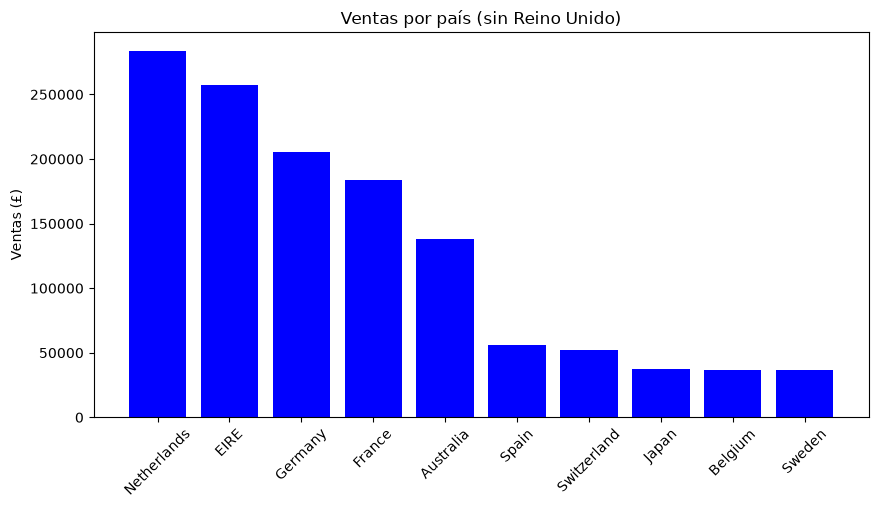

In [28]:
# Grafico de los paises con mas ventas y menos ventas

graficos.ventas_por_pais()

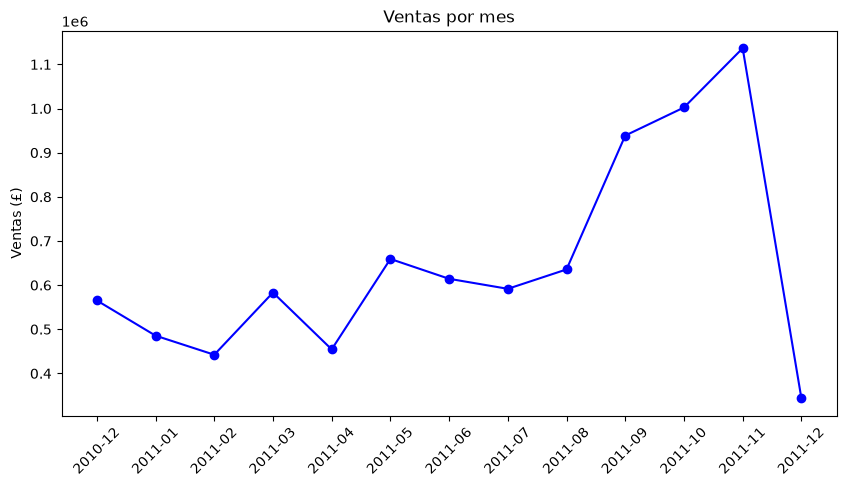

In [29]:
# Grafico de ventas por mes

graficos.ventas_por_mes()

**Interpretacion:** Diciembre de 2011 baja porque los datos terminan el 9 de diciembre (mes incompleto), no porque las ventas caigan. El crecimiento fuerte empieza en septiembre y llega al máximo en noviembre (£1.14 millones).

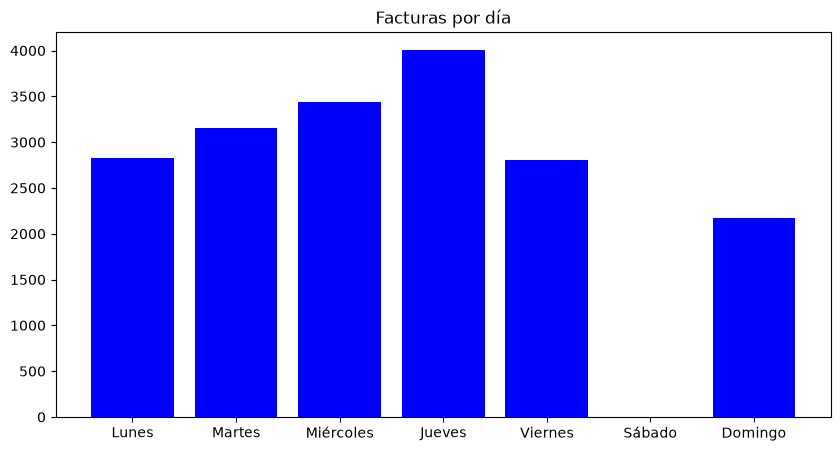

In [30]:
# Grafico de facturas por dia de lasemana

graficos.facturas_por_dia()

**Interpretacion:** No hay facturas los sábados en todo el dataset y el jueves es el día más fuerte (4003 facturas).

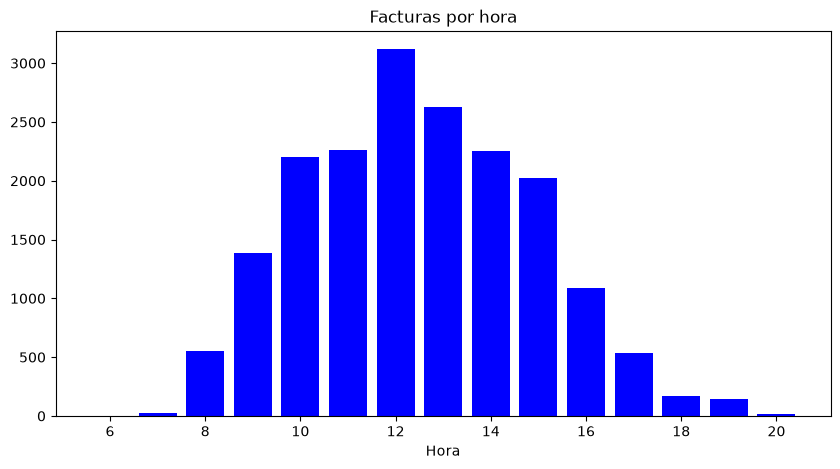

In [31]:
# Grafico de facturas por hora

graficos.facturas_por_hora()

**Interpretacion:** Casi todas las compras ocurren entre las 8 y las 17 horas, con el pico al mediodía (12:00, 3118 facturas).

In [32]:
# Mostramos los productos más vendidos, esto se cuenta en cuantas facturas aparece cada producto

graficos.tabla_top_productos()

Description
WHITE HANGING HEART T-LIGHT HOLDER    1978
REGENCY CAKESTAND 3 TIER              1703
JUMBO BAG RED RETROSPOT               1600
PARTY BUNTING                         1379
ASSORTED COLOUR BIRD ORNAMENT         1375
LUNCH BAG RED RETROSPOT               1289
SET OF 3 CAKE TINS PANTRY DESIGN      1146
JUMBO BAG VINTAGE DOILY               1080
LUNCH BAG  BLACK SKULL.               1052
LUNCH BAG SUKI DESIGN                 1043
Name: InvoiceNo, dtype: int64

----

### 3. Importamos las clases de las Reglas de Asociación

In [13]:
import sys, os
import pandas as pd
sys.path.append(os.path.abspath(".."))   # sube de reporte_final a la raíz del proyecto

from reglas_asociacion.apriori import Apriori
from reglas_asociacion.eclat import Eclat
from reglas_asociacion.fp_growth import FPGrowth

-------

### 4. Regla de Asociación: Apriori

In [ ]:
# Se prepara el dataset para obtener las facturas y productos que se venderán juntos

ventas = pd.read_csv("../processed/2mil_online_retail.csv")

ventas = ventas.dropna(subset=["Description"])
ventas["Description"] = (
    ventas["Description"].str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
)
ventas = ventas[~ventas["InvoiceNo"].astype(str).str.startswith("C")]

df = pd.crosstab(ventas["InvoiceNo"], ventas["Description"]).gt(0)
df = df.loc[:, df.mean() >= 0.02]

print("Filas del CSV:", len(ventas))
print("Facturas:", df.shape[0], "| Productos:", df.shape[1])

Filas del CSV: 2000
Facturas: 90 | Productos: 450


In [8]:
# Llamamos al modelo Apriori para obtener los conjuntos de productos que se venden juntos

modelo_apriori = Apriori(df, min_support=0.03, min_confidence=0.5, max_len=2)
modelo_apriori.ajustar()
print("Reglas generadas:", len(modelo_apriori.rules))

Reglas generadas: 134


In [9]:
# Resultado de las reglas generadas por el modelo Apriori, ordenadas por elevación de mayor a menor

resultado = modelo_apriori.resumen().sort_values("Elevación", ascending=False)
resultado.head(20)

,Antecedente,Consecuente,Soporte,Confianza,Elevación
111,SET/3 RED GINGHAM ROSE STORAGE BOX,RED GINGHAM ROSE JEWELLERY BOX,0.033333,1.00,30.0
78,KNITTED UNION FLAG HOT WATER BOTTLE,RETROSPOT HEART HOT WATER BOTTLE,0.033333,1.00,30.0
51,FAMILY PHOTO FRAME CORNICE,PHOTO FRAME CORNICE,0.033333,1.00,30.0
50,PHOTO FRAME CORNICE,FAMILY PHOTO FRAME CORNICE,0.033333,1.00,30.0
79,RETROSPOT HEART HOT WATER BOTTLE,KNITTED UNION FLAG HOT WATER BOTTLE,0.033333,1.00,30.0
47,EDWARDIAN PARASOL BLACK,EDWARDIAN PARASOL NATURAL,0.033333,1.00,30.0
46,EDWARDIAN PARASOL NATURAL,EDWARDIAN PARASOL BLACK,0.033333,1.00,30.0
110,RED GINGHAM ROSE JEWELLERY BOX,SET/3 RED GINGHAM ROSE STORAGE BOX,0.033333,1.00,30.0
86,LUNCH BAG BLACK SKULL.,SILVER STARS TABLE DECORATION,0.033333,0.75,22.5
56,HAND WARMER OWL DESIGN,HAND WARMER BIRD DESIGN,0.033333,0.75,22.5


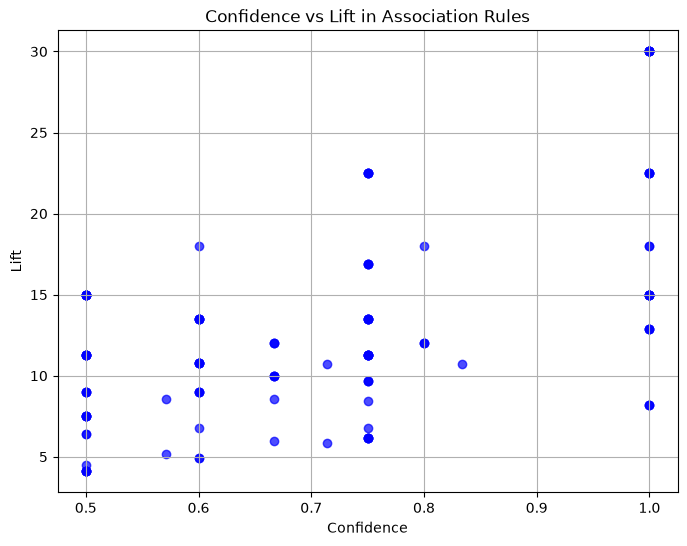

In [10]:
# Grafica de dispersión de las reglas generadas por el modelo Apriori, mostrando soporte vs confianza

modelo_apriori.graficar_dispersion()

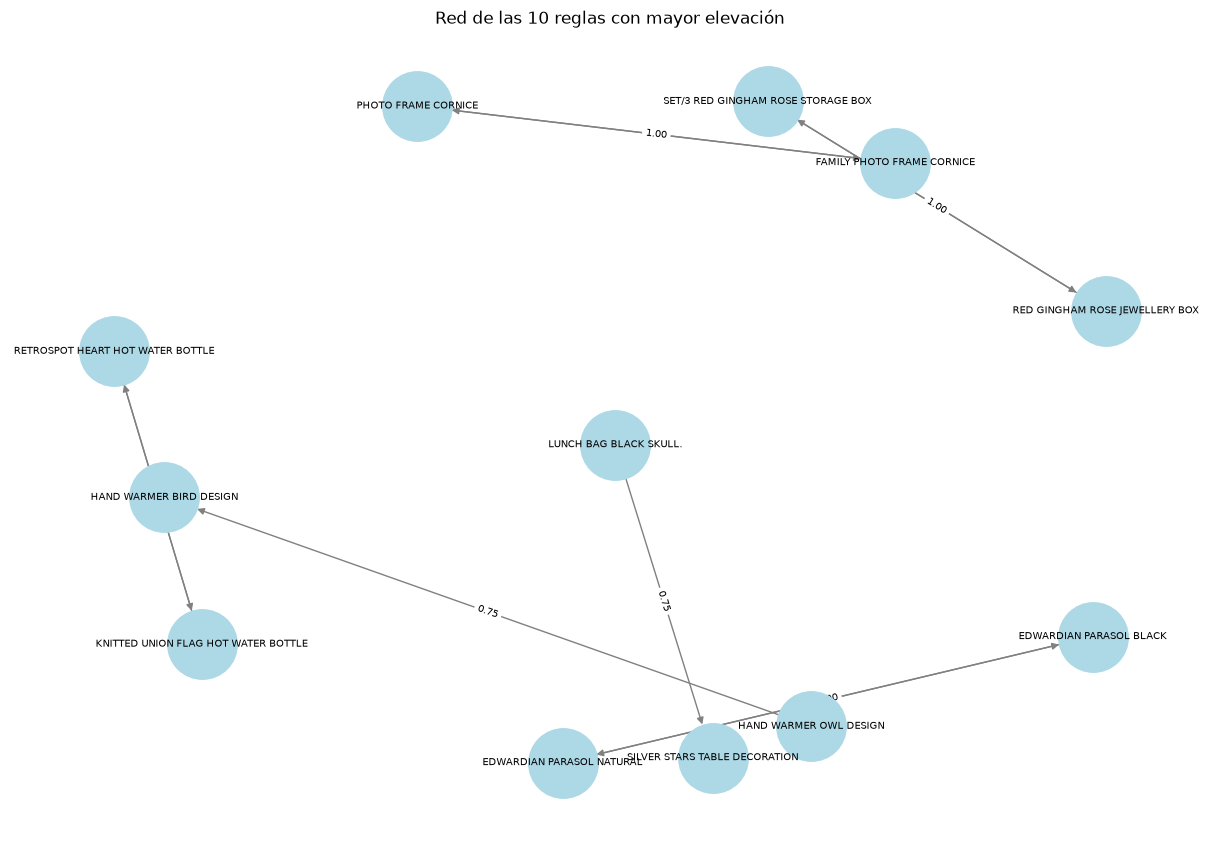

In [ ]:
# Grafica de las reglas generadas por el modelo Apriori, mostrando los productos y sus relaciones

modelo_apriori.graficar_red(top=10)

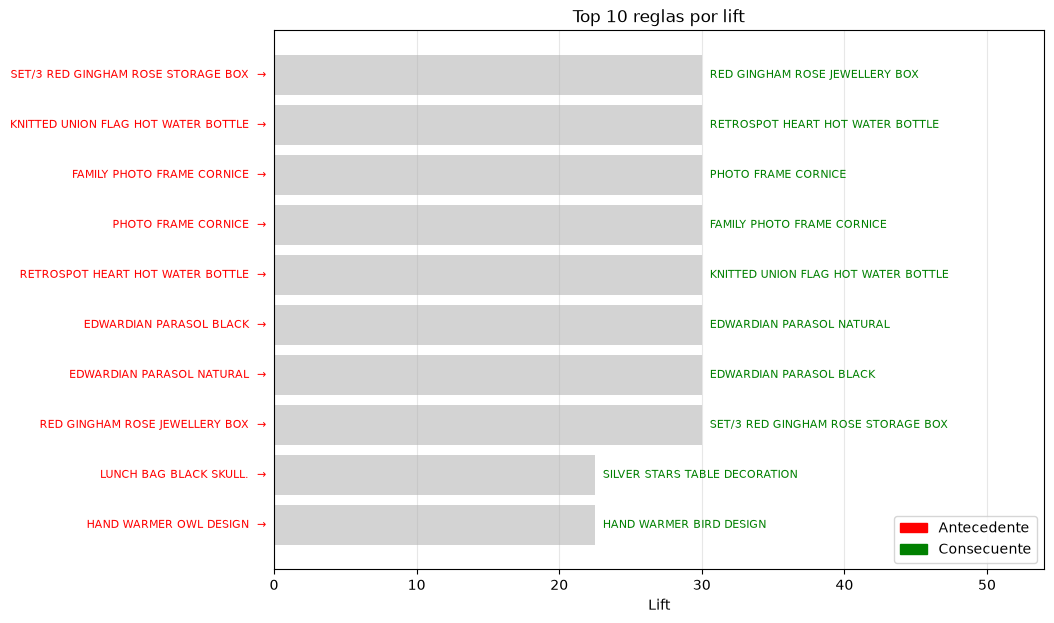

In [12]:
# Grafica de barras de las reglas generadas por el modelo Apriori, mostrando los productos y sus relaciones

modelo_apriori.graficar_barras(top=10)

----

### 5. Regla de Asociación: ECLAT

In [ ]:
# Llamado al modelo Eclat para generar reglas de asociación

modelo = Eclat(min_support=3, min_confidence=0.5)
modelo.load_csv("../processed/2mil_online_retail.csv", transaction_col="InvoiceNo", item_col="Description")
modelo.fit()
reglas = modelo.generate_rules()

print("Transacciones:           ", len(modelo.transactions))
print("Productos distintos:     ", len(modelo.item_tidset))
print("Soporte mínimo (abs):    ", modelo.min_support)
print("Itemsets frecuentes:     ", len(modelo.frequent_itemsets))
print("Reglas generadas:        ", len(modelo.rules))

Transacciones:            90
Productos distintos:      1126
Soporte mínimo (abs):     3
Itemsets frecuentes:      318
Reglas generadas:         370


**Interpretación:** La muestra contiene 90 facturas con 1,126 productos distintos. Con un soporte mínimo de 3 facturas, el algoritmo ECLAT encontró 318 itemsets frecuentes (productos solos y combinaciones que se compran juntos) y generó 370 reglas de asociación con confianza mínima de 0,5. Como la mayoría de los productos aparece en muy pocas facturas, los patrones son ilustrativos por el tamaño reducido de la muestra.

In [ ]:
# Aqui se muestran las facturas con mayor soporte, es decir, los conjuntos de productos que más se venden juntos

combos = [(sorted(k), v) for k, v in modelo.frequent_itemsets.items() if len(k) >= 2]
for items, sup in sorted(combos, key=lambda x: -x[1])[:15]:
    print(sup, "facturas ->", " + ".join(items))

5 facturas -> PARTY BUNTING + SPOTTY BUNTING
5 facturas -> PARTY BUNTING + REGENCY CAKESTAND 3 TIER
5 facturas -> JUMBO BAG VINTAGE DOILY + LUNCH BAG VINTAGE DOILY
4 facturas -> PARTY BUNTING + WHITE HANGING HEART T-LIGHT HOLDER
4 facturas -> LUNCH BAG VINTAGE DOILY + SPOTTY BUNTING
4 facturas -> JUMBO BAG VINTAGE DOILY + SPOTTY BUNTING
4 facturas -> CHOCOLATE HOT WATER BOTTLE + HOT WATER BOTTLE TEA AND SYMPATHY
4 facturas -> 60 TEATIME FAIRY CAKE CASES + PACK OF 72 RETROSPOT CAKE CASES
4 facturas -> 72 SWEETHEART FAIRY CAKE CASES + PACK OF 72 RETROSPOT CAKE CASES
4 facturas -> 60 TEATIME FAIRY CAKE CASES + 72 SWEETHEART FAIRY CAKE CASES
4 facturas -> COOK WITH WINE METAL SIGN + PLEASE ONE PERSON METAL SIGN
4 facturas -> WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH
4 facturas -> ALARM CLOCK BAKELIKE GREEN + ALARM CLOCK BAKELIKE PINK
3 facturas -> PARTY BUNTING + SWEETHEART CAKESTAND 3 TIER
3 facturas -> LOVE BUILDING BLOCK WORD + PARTY BUNTING


In [14]:
# Aqui se muestran las 15 reglas de asociación más fuertes (por confianza) que tengan al menos 2 items en el antecedente y 1 item en el consecuente

reglas.head(15)

,antecedente,consecuente,soporte,confianza,lift
0,"[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...",0.0333,1.0,30.0
1,"[JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOILY]","[JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...",0.0333,1.0,30.0
2,"[JAM MAKING SET PRINTED, SET OF 4 KNICK KNACK ...","[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...",0.0333,1.0,30.0
3,"[JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOI...",0.0333,1.0,30.0
4,"[SET OF 4 KNICK KNACK TINS DOILY, SPOTTY BUNTING]","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...",0.0333,1.0,30.0
5,"[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOILY]","[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...",0.0333,1.0,30.0
6,"[JAM MAKING SET PRINTED, SPOTTY BUNTING]","[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...",0.0333,1.0,30.0
7,"[JUMBO BAG VINTAGE DOILY, LUNCH BAG VINTAGE DO...","[JAM MAKING SET PRINTED, SPOTTY BUNTING]",0.0333,1.0,30.0
8,"[LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK...","[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOILY]",0.0333,1.0,30.0
9,"[JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOI...","[SET OF 4 KNICK KNACK TINS DOILY, SPOTTY BUNTING]",0.0333,1.0,30.0


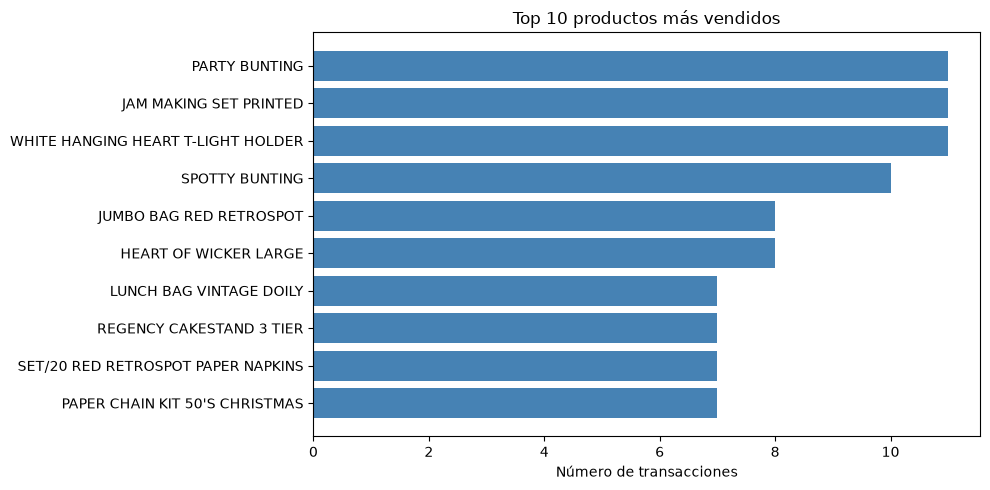

In [ ]:
# Grafica el TOP 10 de productos mas vendidos

modelo.plot_top_items()

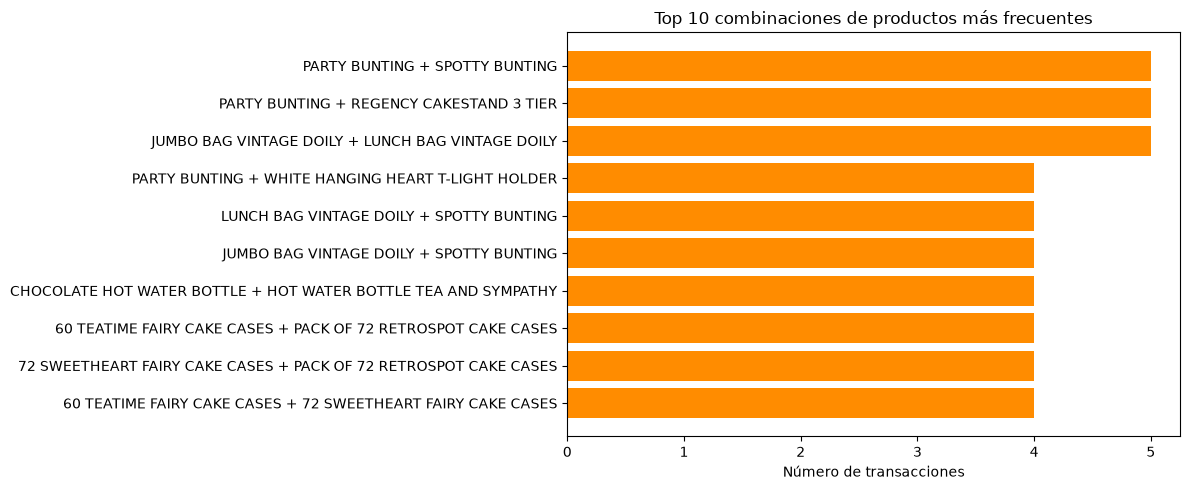

In [ ]:
# Grafica el TOP 10 de las combinaciones de productos más frecuentes (itemsets) que tengan al menos 2 items

modelo.plot_top_itemsets()

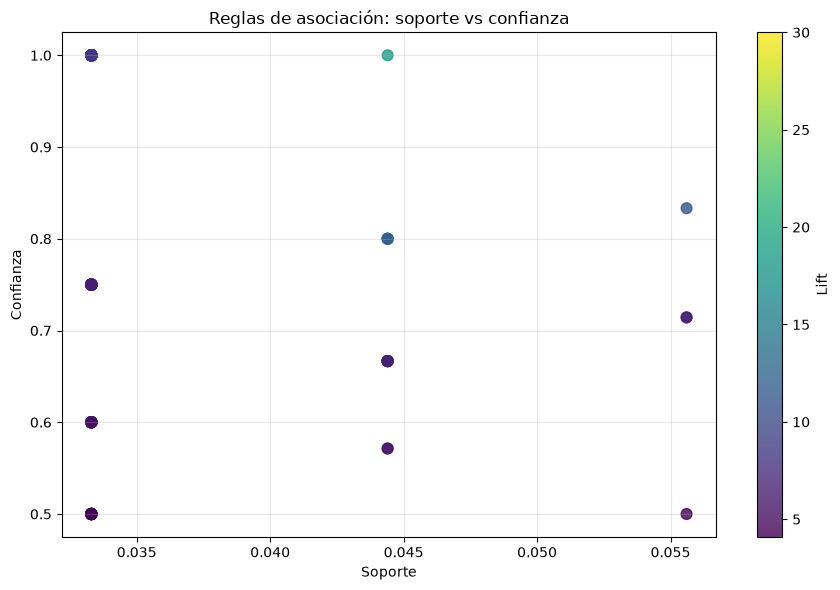

In [ ]:
# Grafica las reglas de asociación con confianza mayor a 0.5 y soporte mayor a 0.01

modelo.plot_rules()

----

### 6. Regla de Asociación: FP-Growth

In [ ]:
# Preparación del dataset para el modelo FPGrowth

ventas = pd.read_csv("../processed/2mil_online_retail.csv")

ventas = ventas.dropna(subset=["Description"])
ventas["Description"] = (
    ventas["Description"].str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
)
ventas = ventas[~ventas["InvoiceNo"].astype(str).str.startswith("C")]

df = pd.crosstab(ventas["InvoiceNo"], ventas["Description"]).gt(0)
df = df.loc[:, df.mean() >= 0.02]

In [15]:
# Llamado al modelo FPGrowth para generar reglas de asociación

modelo_fp = FPGrowth(min_support=0.03, min_confidence=0.5)
patrones = modelo_fp.ejecutar(df)
reglas_fp = modelo_fp.generar_reglas()

print("Patrones frecuentes:", len(patrones))
print("Reglas generadas:", len(reglas_fp))

Patrones frecuentes: 318
Reglas generadas: 370


In [ ]:
# Se muestran los 15 patrones más frecuentes

patrones.head(15)

,support,itemsets
0,0.122222,(WHITE HANGING HEART T-LIGHT HOLDER)
107,0.122222,(PARTY BUNTING)
33,0.122222,(JAM MAKING SET PRINTED)
149,0.111111,(SPOTTY BUNTING)
1,0.088889,(HEART OF WICKER LARGE)
122,0.088889,(JUMBO BAG RED RETROSPOT)
91,0.077778,(SET/20 RED RETROSPOT PAPER NAPKINS)
2,0.077778,(HOT WATER BOTTLE TEA AND SYMPATHY)
108,0.077778,(REGENCY CAKESTAND 3 TIER)
34,0.077778,(PAPER CHAIN KIT 50'S CHRISTMAS)


In [ ]:
# Se observan las reglas generadas por el modelo FPGrowth, ordenadas por elevación

tabla = reglas_fp[["antecedents", "consequents", "support", "confidence", "lift"]].copy()
tabla["antecedents"] = tabla["antecedents"].apply(lambda x: ", ".join(sorted(x)))
tabla["consequents"] = tabla["consequents"].apply(lambda x: ", ".join(sorted(x)))
tabla.head(15)

,antecedents,consequents,support,confidence,lift
127,"KNITTED UNION FLAG HOT WATER BOTTLE, SCOTTIE D...",RETROSPOT HEART HOT WATER BOTTLE,0.033333,1.0,30.0
45,WOODEN PICTURE FRAME WHITE FINISH,"WOOD 2 DRAWER CABINET WHITE FINISH, WOODEN FRA...",0.033333,1.0,30.0
210,"JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK ...","JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOILY",0.033333,1.0,30.0
263,"JUMBO BAG VINTAGE DOILY, SET OF 4 KNICK KNACK ...","JAM MAKING SET PRINTED, LUNCH BAG VINTAGE DOIL...",0.033333,1.0,30.0
264,"JAM MAKING SET PRINTED, JUMBO BAG VINTAGE DOILY","LUNCH BAG VINTAGE DOILY, SET OF 4 KNICK KNACK ...",0.033333,1.0,30.0
278,"LUNCH BAG SPACEBOY DESIGN, PAPER CHAIN KIT 50'...",VINTAGE CHRISTMAS GIFT SACK,0.033333,1.0,30.0
281,VINTAGE CHRISTMAS GIFT SACK,"LUNCH BAG SPACEBOY DESIGN, PAPER CHAIN KIT 50'...",0.033333,1.0,30.0
159,SET/3 RED GINGHAM ROSE STORAGE BOX,RED GINGHAM ROSE JEWELLERY BOX,0.033333,1.0,30.0
158,RED GINGHAM ROSE JEWELLERY BOX,SET/3 RED GINGHAM ROSE STORAGE BOX,0.033333,1.0,30.0
157,FAMILY PHOTO FRAME CORNICE,PHOTO FRAME CORNICE,0.033333,1.0,30.0
